# Support Vector Machines (SVM)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/konstantin-schekotihin/dl_course/blob/master/AI-ML/06_SVM.ipynb)

In [1]:
# Setup & configuration (skip in presentation slides)
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ipywidgets import interact
from sklearn import svm
from sklearn.datasets import make_blobs
import sklearn.model_selection as sel
from sklearn.model_selection import cross_validate, StratifiedKFold
import sklearn.metrics as mt
from sklearn.preprocessing import OneHotEncoder, LabelBinarizer

# Course helpers: installed from PyPI in Colab, from the repository's .venv locally
import sys
if "google.colab" in sys.modules:
    %pip install -q dl-course
from dl_course import aiml as hp
hp.setup_theme()

## 1. Geometric Foundations of Separating Hyperplanes

- For binary classification with targets $t_n \in \{-1, +1\}$, we seek a linear decision surface (separate bias, $\mathbf{x}, \mathbf{w} \in \mathbb{R}^D$)

$$
y(\mathbf{x}) = \mathbf{w}^\mathrm{T}\mathbf{x} + w_0 = 0
$$

  and classify a point by the sign of $y(\mathbf{x})$.

> 💡 **Key Takeaway:** Rather than finding *any* arbitrary separating boundary, Support Vector Machines find the hyperplane that maximizes the **geometric margin**—the distance to the closest training observations.


### Extending Beyond Linear Separability

- Real-world datasets are rarely perfectly linearly separable.
- Support Vector Machines address this via two key mechanisms:
  1. **Soft Margins (Slack Variables $\xi_n$)**: Tolerate a controlled budget of margin violations and classification errors.
  2. **The Kernel Trick**: Implicitly project inputs into high-dimensional feature spaces where non-linear patterns become linearly separable.


### Hyperplanes & Decision Surfaces

- Recall the linear decision boundary of the single-layer perceptron *(from Lecture 04)*.
- In a $D$-dimensional space, a **hyperplane** is an affine flat subspace of dimension $D-1$:
  - $D = 2$: a straight line.
  - $D = 3$: a flat 2D plane.
  - $D > 3$: a $(D-1)$-dimensional linear manifold.

- Mathematical definition defined by weight vector $\mathbf{w} \in \mathbb{R}^D$ and bias $w_0 \in \mathbb{R}$:

$$
\mathbf{w}^\mathrm{T}\mathbf{x} + w_0 = 0
$$


### Separating Hyperplanes & Decision Rules

- A hyperplane divides feature space into two half-spaces:
  - $\mathbf{w}^\mathrm{T}\mathbf{x} + w_0 > 0$: assigns class $+1$.
  - $\mathbf{w}^\mathrm{T}\mathbf{x} + w_0 < 0$: assigns class $-1$.

- For linearly separable training points $\{(\mathbf{x}_n, t_n)\}_{n=1}^N$ with $t_n \in \{-1, +1\}$, a separating hyperplane satisfies:

$$
t_n (\mathbf{w}^\mathrm{T}\mathbf{x}_n + w_0) > 0, \quad \forall n = 1, \dots, N
$$


In [2]:
# Generate linearly separable synthetic dataset (two Gaussian clusters)
X, y = make_blobs(n_samples=40, centers=2, cluster_std=(1, 1), random_state=3)
xlim, ylim = hp.get_boundaries(X)

interactive(children=(Checkbox(value=False, description='show'), Output()), _dom_classes=('widget-interact',))

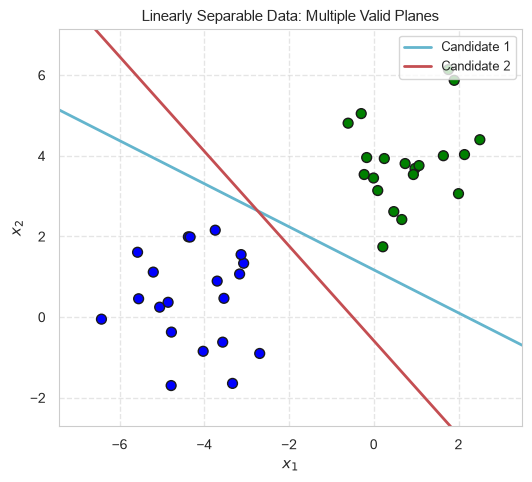

In [3]:
interact(lambda show=False: hp.plot_svm_separating_plane(X, y, xlim, ylim, show=show), show=False);

### Vector Norms & Orthogonal Distance

- The perpendicular distance from observation $\mathbf{x}_n$ to hyperplane $\mathbf{w}^\mathrm{T}\mathbf{x} + w_0 = 0$ is:

$$
\text{dist}(\mathbf{x}_n) = \frac{t_n (\mathbf{w}^\mathrm{T}\mathbf{x}_n + w_0)}{\|\mathbf{w}\|}
$$

- Here $\|\mathbf{w}\| = \sqrt{\sum_{i=1}^{D} w_i^2}$ represents the Euclidean ($L_2$) norm of the normal vector.


## 2. The Maximal Margin Classifier

- The **margin** $M$ is the minimum distance from the separating hyperplane to any training sample.
- We formulate the optimization to maximize margin $M$:

$$
\max_{\mathbf{w}, w_0, M} M \quad \text{subject to } \frac{t_n (\mathbf{w}^\mathrm{T}\mathbf{x}_n + w_0)}{\|\mathbf{w}\|} \ge M, \quad \forall n
$$

- Fixing $M \|\mathbf{w}\| = 1$, maximizing $M = \frac{1}{\|\mathbf{w}\|}$ is equivalent to minimizing $\frac{1}{2}\|\mathbf{w}\|^2$:

$$
\min_{\mathbf{w}, w_0} \frac{1}{2} \|\mathbf{w}\|^2 \quad \text{subject to } t_n (\mathbf{w}^\mathrm{T}\mathbf{x}_n + w_0) \ge 1, \quad \forall n = 1, \dots, N
$$


### Support Vectors & Margin Constraints

- Points satisfying $t_n (\mathbf{w}^\mathrm{T}\mathbf{x}_n + w_0) = 1$ lie precisely on the margin boundary.
- These critical boundary observations are called **support vectors**.

> 💡 **Key Takeaway:** The optimal decision boundary depends solely on the support vectors. Moving or removing any non-support vector data point has zero impact on the final decision boundary!


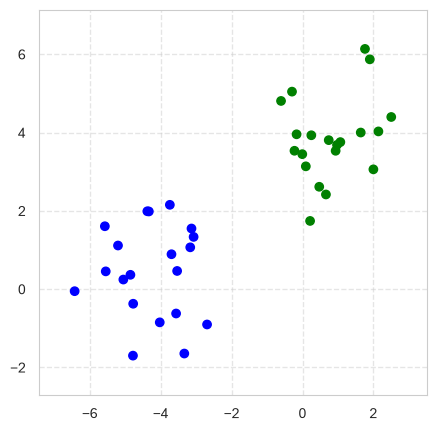

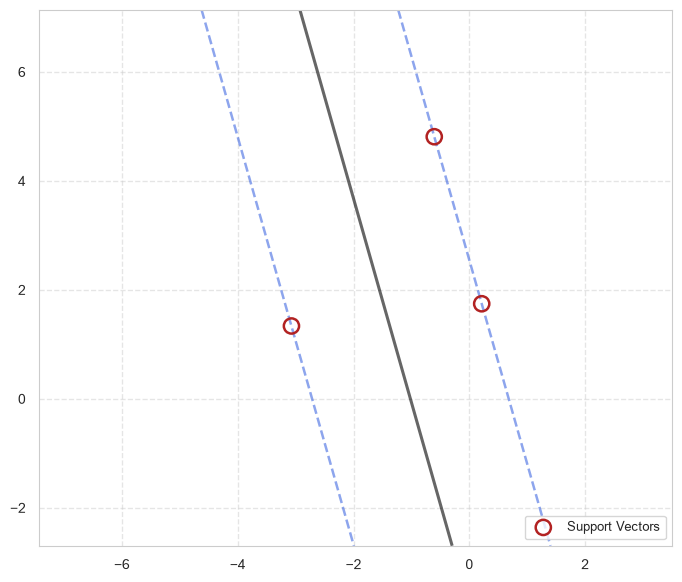

In [4]:
fig = plt.figure(figsize=(5, 5))
plt.xlim(xlim)
plt.ylim(ylim)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=hp.cm_binary)

# Fit linear SVM model
m = svm.SVC(kernel='linear')
m.fit(X, y)

hp.plot_svm_margins(m, xlim=xlim, ylim=ylim)

## 3. Soft-Margin Support Vector Classifier

### The Need for Soft Margins

- Strict maximal margin classification fails when:
  - The training data are not linearly separable.
  - Outliers or noise cause severe overfitting and dramatically shrink the margin.

- **Solution**: Introduce non-negative **slack variables** $\xi_n \ge 0$ allowing points to penetrate the margin.


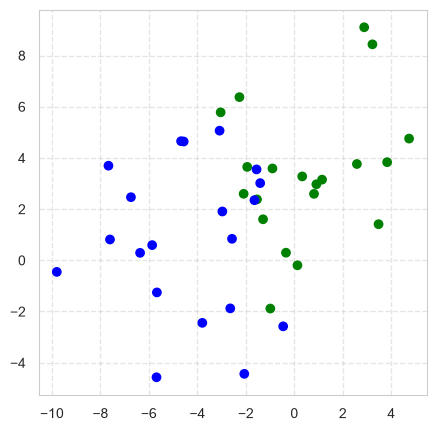

In [5]:
# generates data set (two Gaussians) for visualization purposes
X_m, y_m = make_blobs(n_samples=40, centers=2, cluster_std=(2.5, 2.5), random_state=3)
xlim_m, ylim_m = hp.get_boundaries(X_m)
fig = plt.figure(figsize=(5, 5))
plt.scatter(X_m[:, 0], X_m[:, 1], c=y_m, cmap=hp.cm_binary);

### Optimization with Slack Variables

- Slack variable interpretation for observation $n$:
  - $\xi_n = 0$: sample is correctly classified outside the margin.
  - $0 < \xi_n \le 1$: sample penetrates the margin but remains on the correct side.
  - $\xi_n > 1$: sample crosses the decision boundary (misclassified).

- **Primal Objective with Soft Margin**:

$$
\min_{\mathbf{w}, w_0, \boldsymbol{\xi}} \frac{1}{2} \|\mathbf{w}\|^2 + C \sum_{n=1}^{N} \xi_n \quad \text{subject to } t_n (\mathbf{w}^\mathrm{T}\mathbf{x}_n + w_0) \ge 1 - \xi_n, \quad \xi_n \ge 0
$$


### The Regularization Parameter $C$

- The hyperparameter $C > 0$ weights the slack penalty $C \sum_{n=1}^N \xi_n$ in the primal objective (the formulation used by `sklearn.svm.SVC`) and controls the trade-off between margin size and slack violations:
  - **Large $C$**: Heavy penalty on slack violations $\xi_n$. Yields narrow margins, closely fitting training data (risk of overfitting).
  - **Small $C$**: Permits greater slack violations. Yields wider margins and smoother boundaries (greater tolerance for noise).

> ⚠️ **Important:** Always standardize features before training an SVM; otherwise, features with larger scales will dominate the margin!


### Empirical Effect of the Regularization Parameter $C$

- Linear SVMs fitted to the overlapping clusters for $C \in \{1, 0.5, 0.25, 0.01\}$: the margin widens as $C$ decreases.

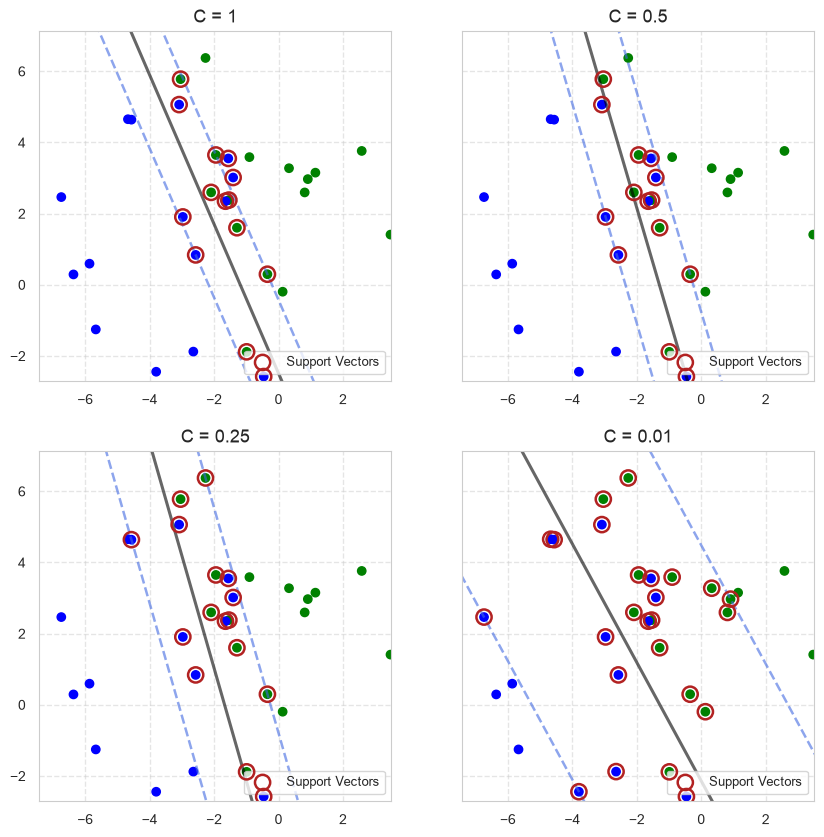

In [6]:
C = [1, 0.5, 0.25, 0.01]

fig, ax = plt.subplots(2, 2, figsize=(10, 10), sharey=True, subplot_kw=dict(xlim=xlim, ylim=ylim))
i = 0
for a in ax.flatten():
    a.scatter(X_m[:, 0], X_m[:, 1], c=y_m, cmap=hp.cm_binary)
    a.set_title(f'C = {C[i]}')
    
    # Fit the model
    m = svm.SVC(kernel='linear', C=C[i])
    m.fit(X_m, y_m)
    i += 1
    
    hp.plot_svm_margins(m, ax=a, xlim=xlim_m, ylim=ylim_m)

## 4. Non-Linear Decision Boundaries & The Kernel Trick
- Problem:
    + When the classes are not linearly separable, even the soft-margin relaxation is not sufficient

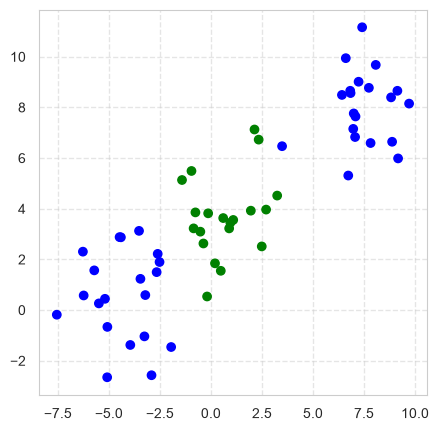

In [7]:
# generates data set (two Gaussians) for visualization purposes
X_h, y_h = make_blobs(n_samples=60, centers=3, cluster_std=(1.5, 1.5, 1.5), random_state=3)
y_h = np.where(y_h == 2, 1, y_h)
xlim_h, ylim_h = hp.get_boundaries(X_h)

fig = plt.figure(figsize=(5, 5))
plt.scatter(X_h[:, 0], X_h[:, 1], c=y_h, cmap=hp.cm_binary);

### Non-Linear Feature Space Expansion

- Solution:
    + Enlarge the space of features using different transformations, like $x_1, x_1^2, x_1^3, x_1 x_2, x_2, \dots$
    + Fit a support-vector classifier in the enlarged space
- This procedure results in non-linear decision boundaries in the original space

### The Kernel Trick

- The dual optimization problem depends solely on **inner products** between feature vectors:

$$
k(\mathbf{x}_n, \mathbf{x}_m) = \boldsymbol{\phi}(\mathbf{x}_n)^\mathrm{T} \boldsymbol{\phi}(\mathbf{x}_m)
$$

- **The Kernel Trick**: Compute high-dimensional inner products directly in input space via kernel function $k(\mathbf{x}, \mathbf{x}') $ without explicitly mapping into high-dimensional space $\boldsymbol{\phi}(\mathbf{x})$.
- **Polynomial Kernel**: $k(\mathbf{x}, \mathbf{x}') = (\mathbf{x}^\mathrm{T}\mathbf{x}' + c)^d$, where $d \in \mathbb{N}$ is the polynomial degree and $c \ge 0$ balances higher-order vs. lower-order terms.


### The Radial Basis Function (RBF / Gaussian) Kernel

- Corresponds to an infinite-dimensional feature space mapping:

$$
k(\mathbf{x}, \mathbf{x}') = \exp\left( -\gamma \|\mathbf{x} - \mathbf{x}'\|^2 \right)
$$

- Parameter $\gamma = \frac{1}{2\sigma^2} > 0$ governs the radius of influence:
  - **Large $\gamma$**: Narrow bell curves, high variance (complex, wiggly boundaries).
  - **Small $\gamma$**: Broad Gaussian curves, high bias (smooth, quasi-linear boundaries).


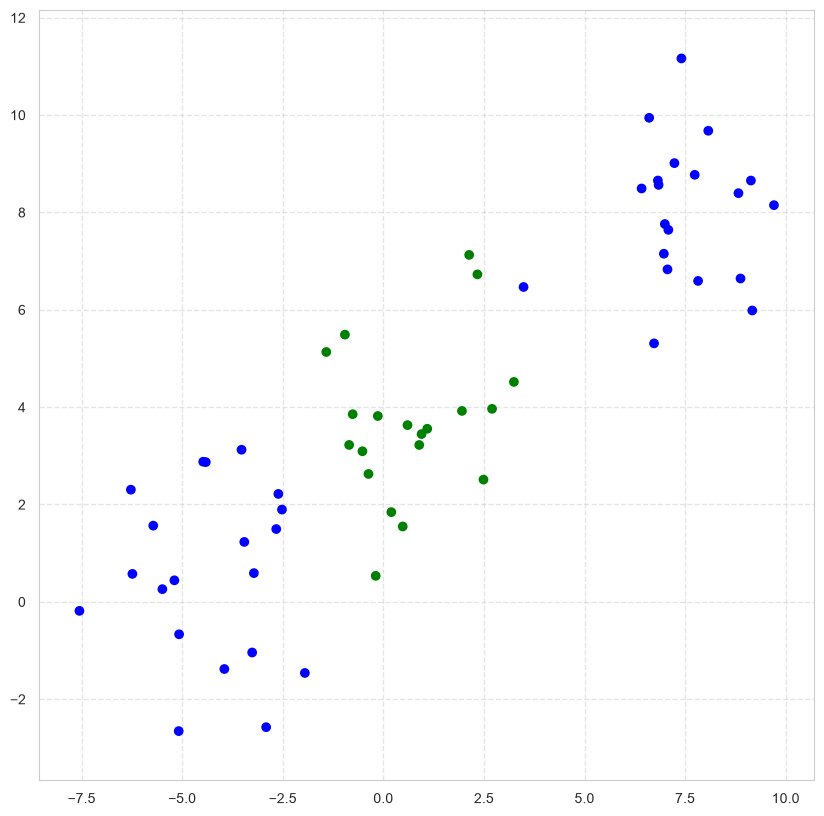

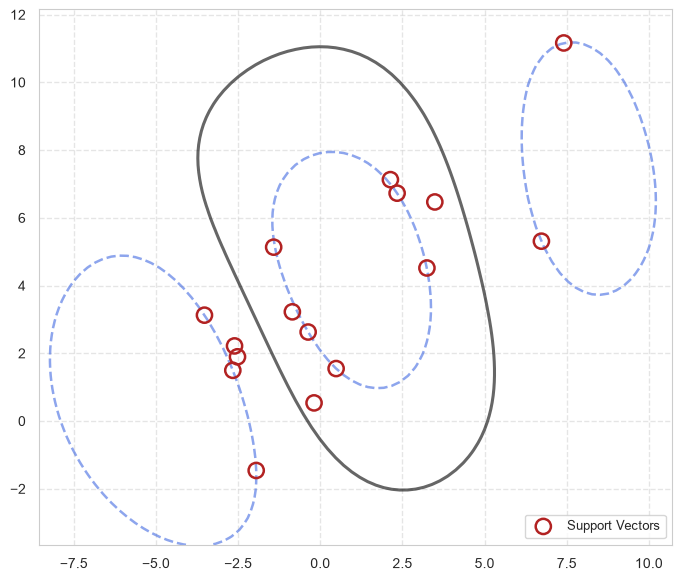

In [8]:
fig = plt.figure(figsize=(10, 10))
plt.xlim(xlim_h)
plt.ylim(ylim_h)
plt.scatter(X_h[:, 0], X_h[:, 1], c=y_h, cmap=hp.cm_binary)

m = svm.SVC(kernel='rbf', C=1, degree=10, gamma=0.05)
m.fit(X_h, y_h)

hp.plot_svm_margins(m, xlim=xlim_h, ylim=ylim_h)

## 5. Applied Case Study: Breast Cancer Recurrence

In [9]:
# Load breast cancer dataset 
bc = pd.read_csv(hp.get_data_path("breast-cancer.csv"))
bc.head()


,recurrence,age,menopause,tumor-size,inv-nodes,node-caps,deg-malig,breast,breast-quad,irradiat
0,no-recurrence-events,30-39,premeno,30-34,0-2,no,3,left,left_low,no
1,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,right,right_up,no
2,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,left,left_low,no
3,no-recurrence-events,60-69,ge40,15-19,0-2,no,2,right,left_up,no
4,no-recurrence-events,40-49,premeno,0-4,0-2,no,2,right,right_low,no


In [10]:
bc.describe(include='all')

,recurrence,age,menopause,tumor-size,inv-nodes,node-caps,deg-malig,breast,breast-quad,irradiat
count,286,286,286,286,286,286,286.000000,286,286,286
unique,2,6,3,11,7,3,NaN,2,6,2
top,no-recurrence-events,50-59,premeno,30-34,0-2,no,NaN,left,left_low,no
freq,201,96,150,60,213,222,NaN,152,110,218
mean,NaN,NaN,NaN,NaN,NaN,NaN,2.048951,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,0.738217,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,NaN,NaN,NaN


In [11]:
bc = bc.copy()  # Use cached DataFrame
y_bc = bc.pop("recurrence").values
X_bc = bc.values

In [12]:
ohe = OneHotEncoder()
X_bc = ohe.fit_transform(X_bc).toarray()

In [13]:
X_train, X_test, y_train, y_test = sel.train_test_split(X_bc, y_bc, test_size=0.25, random_state=123, stratify=y_bc)
m = svm.SVC(kernel='sigmoid', gamma='scale', C=0.85, 
            class_weight={'no-recurrence-events':.25, 'recurrence-events':.75})
m.fit(X_train, y_train)
y_pred = m.predict(X_test)
print(mt.classification_report(y_test, y_pred))

                      precision    recall  f1-score   support

no-recurrence-events       0.93      0.78      0.85        51
   recurrence-events       0.62      0.86      0.72        21

            accuracy                           0.81        72
           macro avg       0.78      0.82      0.79        72
        weighted avg       0.84      0.81      0.81        72



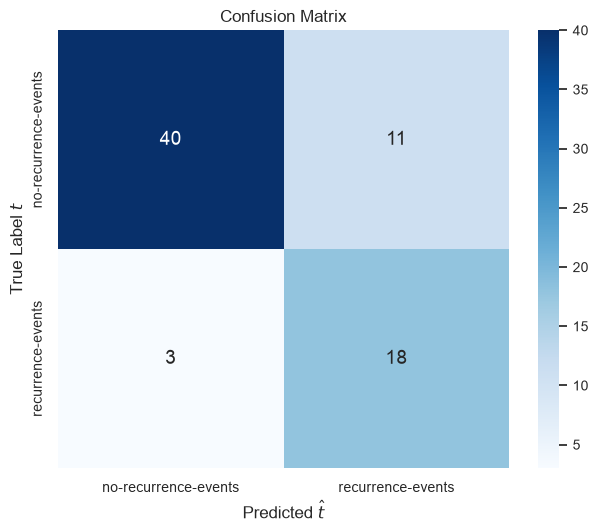

In [14]:
hp.plot_confusion_matrix(y_test, y_pred, labels=["no-recurrence-events", "recurrence-events"])


Average F1 from 10-fold CV: 0.5229588964139049


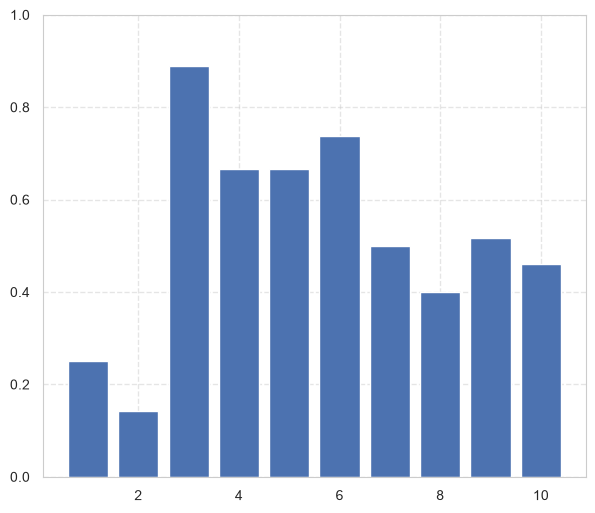

In [15]:
y_l = LabelBinarizer().fit_transform(y_bc).flatten()

m = svm.SVC(kernel='rbf', gamma='scale', C=1, 
            class_weight={0:.25, 1:.75})
res = cross_validate(m, X_bc, y_l, cv=StratifiedKFold(n_splits=10),  scoring=["precision", 'recall', 'f1'])
print("Average F1 from 10-fold CV: {}".format(np.average(res['test_f1'])))
plt.figure(figsize=(7,6))
plt.bar(np.arange(1,11), res['test_f1'])
plt.ylim(0,1)
plt.show()

## 6. Algorithm Selection Card: Support Vector Machines (SVM)

| Dimension | Assessment & Practical Guidance |
| :--- | :--- |
| **Best Suited For** | Medium-sized tabular or high-dimensional datasets with intricate non-linear decision boundaries where feature count is high relative to sample size ($D \approx N$). |
| **Key Hyperparameters** | • Regularization $C$: margin violation tolerance (large $C$ = hard margin, small $C$ = soft margin).<br>• Kernel: `linear`, `rbf`, `poly`.<br>• Kernel Coefficient $\gamma$ (`scale`, `auto`, float) for RBF/polynomial kernels. |
| **Interpretability vs. Capacity** | **Low Interpretability / High Capacity**: With RBF kernels, SVM is a highly flexible non-linear estimator; decision boundary is defined geometrically by support vectors. |
| **Critical Pitfalls** | • **Feature Scaling**: Absolute requirement (`StandardScaler`); distance calculations are distorted without normalization.<br>• **Scaling Limits**: Training time scales quadratically to cubically $\mathcal{O}(N^2 - N^3)$ with sample size; slow on $N > 50{,}000$. |

> 💡 **Key Takeaway:** SVMs maximize geometric margins to achieve strong theoretical generalization. Always scale features and tune $C$ and $\gamma$ jointly via cross-validation.